In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd
import time

### Simulación del potencial de una neurona mediante el modelo computacional de Hodgkin y Huxley.

Función `hh_euler` contiene modelo vectorizado en el que la resolución del sistema de EDOs se lleva a cabo mediante integración numérica empleando el método de Euler.

In [17]:
def hh_euler(
    T: float = 400,
    dt: float = 0.01,
    mu: float = 0.0,
    sigma: float = 6.0,
    cte: float = 6.0,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:

    """ Vectorized model in which the system of ODEs is solved through numerical integration using the Euler method.
    
        Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    mu, sigma :
        Parameters of noise I for the neuron.

    cte:
        Constant input current added to the neuron.
        
    plot :
        If True, display the simulation plot. If False, no plot is shown.

    Returns
    -------
    V:
        Membrane potential of the neuron.

    """

    # ======================
    # PARÁMETROS HH
    # ======================
    C = 1.0
    gNa, gK, gL = 120.0, 36.0, 0.3
    ENa, EK, EL = 50.0, -77.0, -54.4

    # ======================
    # FUNCIONES HH
    # ======================
    def get_rates(V):
        am = 0.1*(V+40)/(1 - np.exp(-(V+40)/10))
        bm = 4*np.exp(-(V+65)/18)
        ah = 0.07*np.exp(-(V+65)/20)
        bh = 1/(1 + np.exp(-(V+35)/10))
        an = 0.01*(V+55)/(1 - np.exp(-(V+55)/10))
        bn = 0.125*np.exp(-(V+65)/80)
        return am, bm, ah, bh, an, bn

    # ======================
    # TIEMPO
    # ======================
    n_steps = int(T / dt)
    t_eval = np.linspace(0, T, n_steps)

    # ======================
    # RUIDO (vectorizado)
    # ======================
    I = cte + mu + sigma * np.random.randn(n_steps)

    # ======================
    # INICIALIZACIÓN
    # ======================
    V, m, h, n = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)

    V[0] = -65.0
    am, bm, ah, bh, an, bn = get_rates(V[0])
    m[0] = am/(am+bm)
    h[0] = ah/(ah+bh)
    n[0] = an/(an+bn)

    # ======================
    # BUCLE DE INTEGRACIÓN (Euler)
    # ======================
    for i in range(n_steps - 1):
        am, bm, ah, bh, an, bn = get_rates(V[i])
        m[i+1] = m[i] + (am*(1-m[i]) - bm*m[i]) * dt
        h[i+1] = h[i] + (ah*(1-h[i]) - bh*h[i]) * dt
        n[i+1] = n[i] + (an*(1-n[i]) - bn*n[i]) * dt                                                  
        I_ion = gNa*(m[i]**3)*h[i]*(V[i]-ENa) + gK*(n[i]**4)*(V[i]-EK) + gL*(V[i]-EL)
        V[i+1] = V[i] + (I[i] - I_ion) * dt / C

    # ======================
    # PLOT
    # ======================
    if plot:
        fig, ax1 = plt.subplots(figsize=(10, 6))

        color_v = "tab:blue"
        ax1.set_xlabel("Tiempo (ms)")
        ax1.set_ylabel("Potencial V (mV)", color=color_v)
        ax1.plot(t_eval, V, color=color_v, linewidth=1.5, label="V(t)")
        ax1.tick_params(axis="y", labelcolor=color_v)

        ax2 = ax1.twinx()
        color_i = "tab:orange"
        ax2.set_ylabel("Corriente I (µA/cm²)", color=color_i)
        ax2.plot(t_eval, I, color=color_i, alpha=0.5, linestyle="--", label="I(t)")
        ax2.tick_params(axis="y", labelcolor=color_i)

        plt.title("Dinámica de la Neurona: Potencial y Corriente Inyectada")
        fig.tight_layout()
        plt.show()

    return V

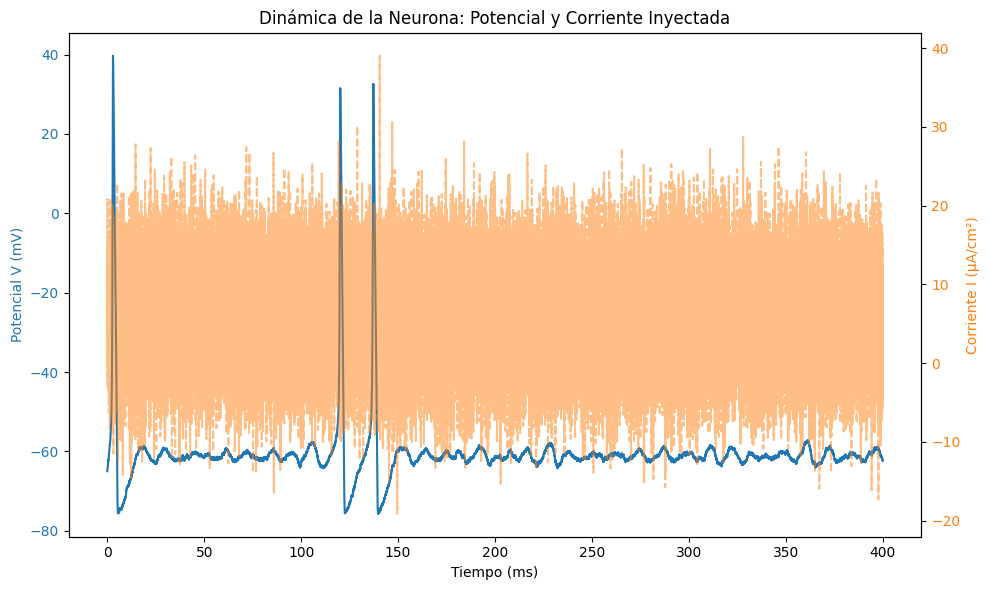

In [13]:
V = hh_euler()

Comprobación de que el paso temporal $dt=0.01$ es suficiente para obtener precisión cuando se trabaja con el modelo anterior:

--- TIEMPOS DE EJECUCIÓN ---
dt = 0.01 ms:   2.227116 s
dt = 0.0001 ms: 168.486152 s (Factor de ralentización: 76.03x)

--- MÉTRICAS DE ERROR (V_001 vs Gran Verdad) ---
Error Absoluto Medio (MAE):   2.3911 mV
Raíz del Error Cuadrático (RMSE): 6.6179 mV
Error Máximo Puntuual:        61.6293 mV


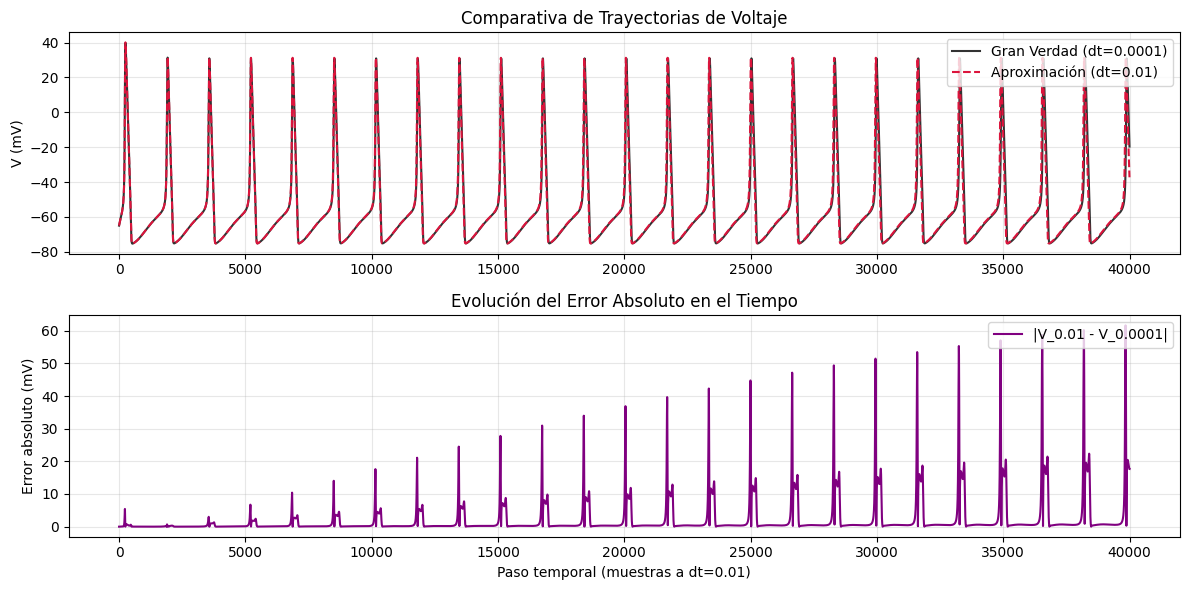

In [15]:
# Ejecución con dt = 0.01 (Aproximación)
t0 = time.perf_counter()
V_001 = hh_euler(dt=0.01, sigma=0.0, cte=7.5, plot=False)
t_001 = time.perf_counter() - t0

# Ejecución con dt = 0.0001 (Referencia / Gran Verdad)
t0 = time.perf_counter()
V_ref_full = hh_euler(dt=0.0001, sigma=0.0, cte=7.5, plot=False)
t_00001 = time.perf_counter() - t0

# Alineación de dimensiones mediante submuestreo (paso 100x)
ratio = int(0.01 / 0.0001)
V_ref = V_ref_full[::ratio]

# Asegurar misma longitud exacta por posibles redondeos de int(T/dt)
min_len = min(len(V_001), len(V_ref))
V_001 = V_001[:min_len]
V_ref = V_ref[:min_len]

# Cálculo de métricas de error
error_abs = np.abs(V_001 - V_ref)
mae = np.mean(error_abs)
rmse = np.sqrt(np.mean((V_001 - V_ref)**2))
max_err = np.max(error_abs)

# Reporte de tiempos y discrepancias
print(f"--- TIEMPOS DE EJECUCIÓN ---")
print(f"dt = 0.01 ms:  {t_001:.6f} s")
print(f"dt = 0.0001 ms: {t_00001:.6f} s (Factor de ralentización: {t_00001/t_001:.2f}x)")

print(f"\n--- MÉTRICAS DE ERROR (V_001 vs Gran Verdad) ---")
print(f"Error Absoluto Medio (MAE):   {mae:.4f} mV")
print(f"Raíz del Error Cuadrático (RMSE): {rmse:.4f} mV")
print(f"Error Máximo Puntuual:        {max_err:.4f} mV")

# Gráfica comparativa visual de la discrepancia
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(V_ref, label='Gran Verdad (dt=0.0001)', color='black', alpha=0.8)
plt.plot(V_001, label='Aproximación (dt=0.01)', color='crimson', linestyle='--')
plt.ylabel('V (mV)')
plt.title('Comparativa de Trayectorias de Voltaje')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(error_abs, color='purple', label='|V_0.01 - V_0.0001|')
plt.xlabel('Paso temporal (muestras a dt=0.01)')
plt.ylabel('Error absoluto (mV)')
plt.title('Evolución del Error Absoluto en el Tiempo')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Spikes en aproximación: 25 | en referencia: 25
Desfase en el primer spike: 0.0176 ms
Desfase en el último spike: -0.3810 ms (t = 398.7 ms)
Deriva: -0.101 ms por cada 100 ms de simulación


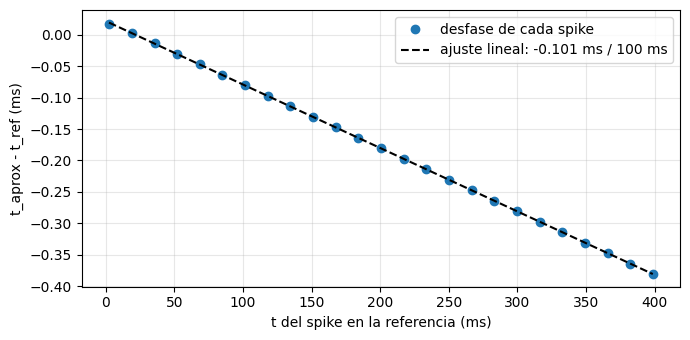

In [22]:
def tiempos_spike(V, dt, umbral=0.0):
    """Instantes de cruce ascendente del umbral, con interpolación lineal (en ms)."""
    V = np.asarray(V)
    idx = np.where((V[:-1] < umbral) & (V[1:] >= umbral))[0]
    frac = (umbral - V[idx]) / (V[idx + 1] - V[idx])
    return (idx + frac) * dt

t_aprox = tiempos_spike(V_001, 0.01)        # dt = 0.01 ms
t_ref   = tiempos_spike(V_ref_full, 1e-4)   # dt = 1e-4 ms, resolución completa

n = min(len(t_aprox), len(t_ref))
desfase = t_aprox[:n] - t_ref[:n]
coef = np.polyfit(t_ref[:n], desfase, 1)
pendiente = coef[0]

print(f"Spikes en aproximación: {len(t_aprox)} | en referencia: {len(t_ref)}")
print(f"Desfase en el primer spike: {desfase[0]:.4f} ms")
print(f"Desfase en el último spike: {desfase[-1]:.4f} ms (t = {t_ref[n-1]:.1f} ms)")
print(f"Deriva: {pendiente*100:.3f} ms por cada 100 ms de simulación")

plt.figure(figsize=(7, 3.5))
plt.plot(t_ref[:n], desfase, 'o', label='desfase de cada spike')
plt.plot(t_ref[:n], np.polyval(coef, t_ref[:n]), 'k--',
         label=f'ajuste lineal: {pendiente*100:.3f} ms / 100 ms')
plt.xlabel('t del spike en la referencia (ms)')
plt.ylabel('t_aprox - t_ref (ms)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

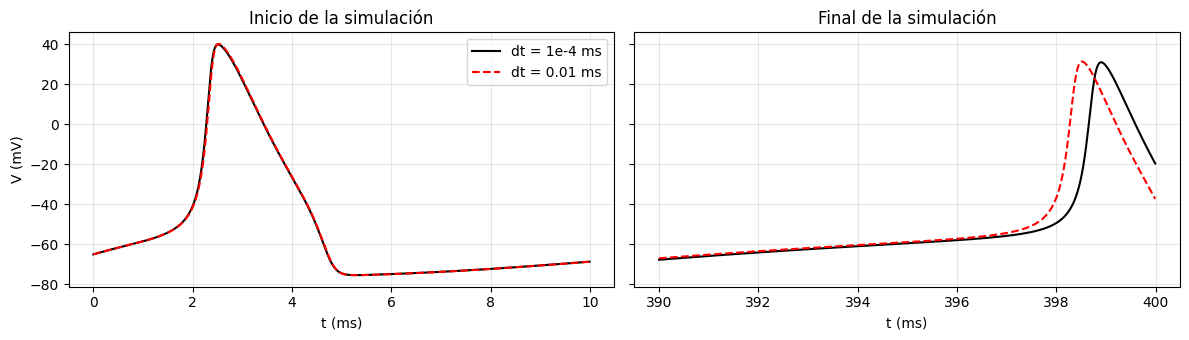

In [20]:
t = np.arange(len(V_001)) * 0.01   # ms
m = len(t)
ventana = 1000                     # 1000 muestras = 10 ms

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (a, b), titulo in zip(axs,
                              [(0, ventana), (m - ventana, m)],
                              ['Inicio de la simulación', 'Final de la simulación']):
    ax.plot(t[a:b], V_ref[a:b], 'k', label='dt = 1e-4 ms')
    ax.plot(t[a:b], V_001[a:b], 'r--', label='dt = 0.01 ms')
    ax.set_title(titulo); ax.set_xlabel('t (ms)'); ax.grid(alpha=0.3)
axs[0].set_ylabel('V (mV)'); axs[0].legend()
plt.tight_layout(); plt.show()

Función `hh_hibrido` contiene un modelo vectorizado en el que se usa el
método de integración exponencial de Moore en las variables de compuerta (m, n, h)
y Runge-Kutta en el potencial, manteniendo un paso temporal uniforme de ∆t =
0,01 ms en todo el sistema. 

In [4]:
def hh_hibrido(
    T: float = 400,
    dt: float = 0.01,
    mu: float = 0.0,
    sigma: float = 4.5,
    cte: float = 7.0,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:
    
    """ The explicit Euler integration is replaced by Moore’s exponential integration method for the gating variables (m, n, and h),
    and by the Runge–Kutta method for the membrane potential, while maintaining a uniform time step of dt = 0.01 ms throughout the system. 
    
        Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    mu, sigma :
        Parameters of noise I for the neuron.

    cte:
        Constant input current added to the neuron.
        
    plot :
        If True, display the simulation plot. If False, no plot is shown.

    Returns
    -------
    V:
        Membrane potential of the neuron.

    """

    # ======================
    # PARÁMETROS HH
    # ======================
    C = 1.0
    gNa, gK, gL = 120.0, 36.0, 0.3
    ENa, EK, EL = 50.0, -77.0, -54.4

    # ======================
    # FUNCIONES HH
    # ======================
    def get_rates(V):
        am = 0.1*(V+40)/(1 - np.exp(-(V+40)/10))
        bm = 4*np.exp(-(V+65)/18)
        ah = 0.07*np.exp(-(V+65)/20)
        bh = 1/(1 + np.exp(-(V+35)/10))
        an = 0.01*(V+55)/(1 - np.exp(-(V+55)/10))
        bn = 0.125*np.exp(-(V+65)/80)
        return am, bm, ah, bh, an, bn

    def dVdt(V,m,h,n,I,I_syn):
        I_ion = gNa*(m**3)*h*(V-ENa) + gK*(n**4)*(V-EK) + gL*(V-EL)
        return (I - I_ion)/C

    # ======================
    # TIEMPO
    # ======================
    n_steps = int(T / dt)
    t_eval = np.linspace(0, T, n_steps)

    # ======================
    # RUIDO (vectorizado)
    # ======================
    I = cte + mu + sigma * np.random.randn(n_steps)

    # ======================
    # INICIALIZACIÓN
    # ======================
    V, m, h, n = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)

    V[0] = -65.0
    am, bm, ah, bh, an, bn = get_rates(V[0])
    m[0] = am/(am+bm)
    h[0] = ah/(ah+bh)
    n[0] = an/(an+bn)

    # ======================
    # BUCLE DE INTEGRACIÓN
    # Variables de compuerta mediante integración exponencial y potencial de membrana con Euler explícito. 
    # ======================
    for i in range(n_steps - 1):

        am, bm, ah, bh, an, bn = get_rates(V[i])

        tau_m = 1.0 / (am + bm)  
        tau_h = 1.0 / (ah + bh)
        tau_n = 1.0 / (an + bn)
        
        m_inf = am / (am + bm)  
        h_inf = ah / (ah + bh)
        n_inf = an / (an + bn)

        #Variables de compuerta mediante integración exponencial
        m[i+1] = m_inf + (m[i] - m_inf) * np.exp(-dt / tau_m) 
        h[i+1] = h_inf + (h[i] - h_inf) * np.exp(-dt / tau_h)                                                   
        n[i+1] = n_inf + (n[i] - n_inf) * np.exp(-dt / tau_n)

        
        k1 = dVdt(V[i], m[i], h[i], n[i], I[i], 0)
        k2 = dVdt(V[i]+ 0.5*dt*k1, m[i], h[i], n[i], I[i], 0)
        k3 = dVdt(V[i]+ 0.5*dt*k2, m[i], h[i], n[i], I[i], 0)
        k4 = dVdt(V[i]+ dt*k3, m[i], h[i], n[i], I[i], 0)

        V[i+1] = V[i] + dt*(k1+2*k2+2*k3+k4)/6     # RK4 para el voltaje

    
    # ======================
    # PLOT
    # ======================
    if plot:
        fig, ax1 = plt.subplots(figsize=(10, 6))

        # Eje principal (Potencial de Membrana)
        color_v = "tab:blue"
        ax1.set_xlabel("Tiempo (ms)")
        ax1.set_ylabel("Potencial V (mV)", color=color_v)
        ax1.plot(t_eval, V, color=color_v, linewidth=1.5, label="V(t)")
        ax1.tick_params(axis="y", labelcolor=color_v)

        # Eje secundario para la Corriente Inyectada
        ax2 = ax1.twinx()
        color_i = "tab:orange"
        ax2.set_ylabel("Corriente I (µA/cm²)", color=color_i)
        ax2.plot(
            t_eval, I, color=color_i, alpha=0.5, linestyle="--", label="I(t)"
        )
        ax2.tick_params(axis="y", labelcolor=color_i)

        plt.title("Dinámica de la Neurona: Potencial y Corriente Inyectada")
        fig.tight_layout()
        plt.show()

    return V

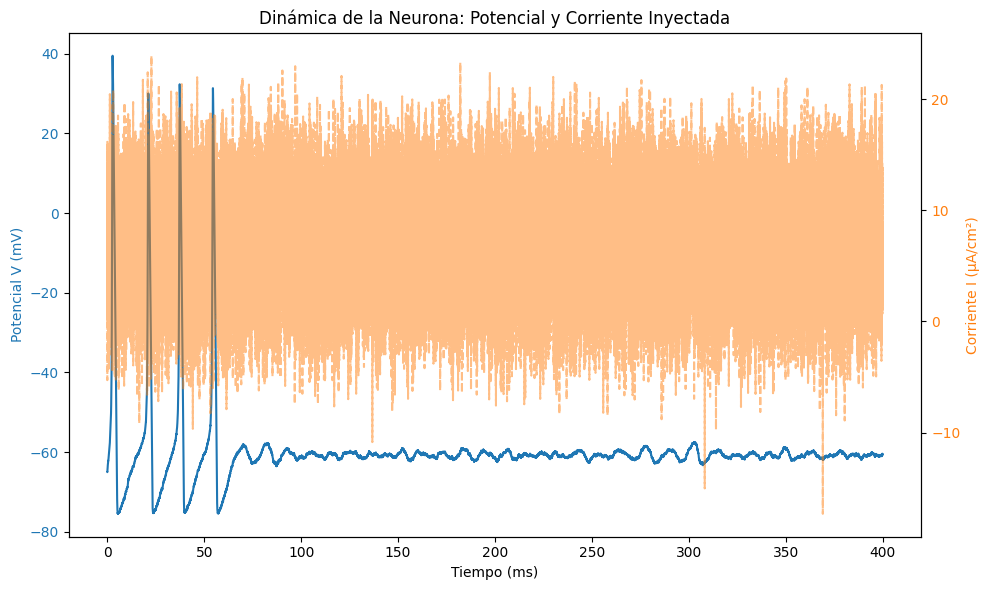

In [33]:
V = hh_hibrido()

Comparación entre el método unificado con Euler y el método hibrido, usando paso temporal $dt= 0.01$ en todo el sistema:

--- TIEMPOS DE EJECUCIÓN (dt = 0.01 ms) ---
Euler puro:         0.663263 s
Moore (canales):    1.036350 s
Relación de tiempo (Euler / Moore): 0.64x

--- DIFERENCIA ENTRE MÉTODOS (Moore vs Euler) ---
Error Absoluto Medio (MAE):       8.746553 mV
Raíz del Error Cuadrático (RMSE): 20.278846 mV
Diferencia Máxima Puntual:        104.239336 mV


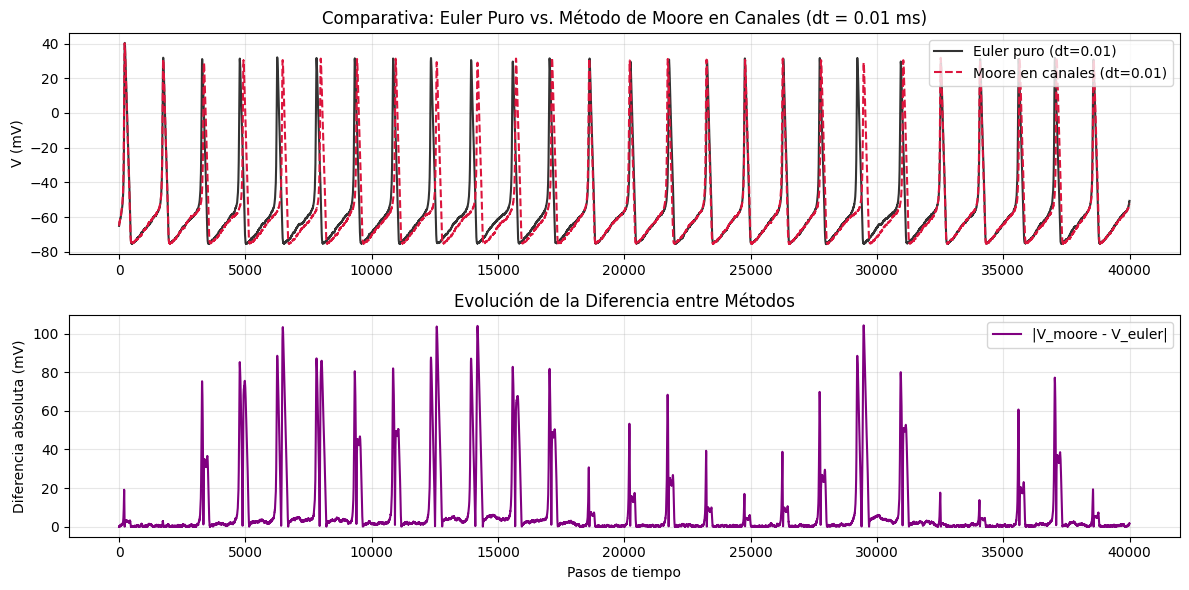

In [12]:
dt_eval = 0.01

# Simulación 1: Euler (potencial y canales con Euler a dt = 0.01)
t0 = time.perf_counter()
V_euler = hh_euler(dt=dt_eval, sigma=6.0, cte=9.0, plot=False)
t_euler = time.perf_counter() - t0

# Simulación 2: Moore + Euler (Canales con Moore a dt = 0.01, potencial con Euler a dt = 0.01)
t0 = time.perf_counter()
V_moore = hh_hibrido(dt=dt_eval, sigma=6.0, cte=9.0, plot=False)
t_moore = time.perf_counter() - t0

# Alineación de dimensiones
min_len = min(len(V_euler), len(V_moore))
V_euler = V_euler[:min_len]
V_moore = V_moore[:min_len]

# Métricas de error y diferencia
error_abs = np.abs(V_moore - V_euler)
mae = np.mean(error_abs)
rmse = np.sqrt(np.mean((V_moore - V_euler)**2))
max_err = np.max(error_abs)


# Reporte de Tiempos y Métricas Corregido
print("--- TIEMPOS DE EJECUCIÓN (dt = 0.01 ms) ---")
print(f"Euler puro:         {t_euler:.6f} s")
print(f"Moore (canales):    {t_moore:.6f} s")
if t_euler > 0:
    speedup = t_euler / t_moore
    print(f"Relación de tiempo (Euler / Moore): {speedup:.2f}x")

print("\n--- DIFERENCIA ENTRE MÉTODOS (Moore vs Euler) ---")
print(f"Error Absoluto Medio (MAE):       {mae:.6f} mV")
print(f"Raíz del Error Cuadrático (RMSE): {rmse:.6f} mV")
print(f"Diferencia Máxima Puntual:        {max_err:.6f} mV")


# Representación Gráfica
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(V_euler, label='Euler puro (dt=0.01)', color='black', alpha=0.8)
plt.plot(V_moore, label='Moore en canales (dt=0.01)', color='crimson', linestyle='--')
plt.ylabel('V (mV)')
plt.title('Comparativa: Euler Puro vs. Método de Moore en Canales (dt = 0.01 ms)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(error_abs, color='purple', label='|V_moore - V_euler|')
plt.xlabel('Pasos de tiempo')
plt.ylabel('Diferencia absoluta (mV)')
plt.title('Evolución de la Diferencia entre Métodos')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Función `hh_multiescala` contiene un esquema mixto multiescala donde la
cinética de los canales iónicos se integra a una escala temporal más lenta (∆t = 0,1 ms)
empleando el promedio local del voltaje, mientras que el potencial V se resuelve a una
escala fina (∆t = 0,01 ms), usando valores interpolados de las variables de compuerta. 

In [58]:
def hh_multiescala(
    T: float = 400,
    dt: float = 0.01,
    mu: float = 0.0,
    sigma: float = 2.0,
    cte: float = 7.0,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:
    
    """  A multiscale hybrid scheme in which the kinetics of the ion channels are integrated on a slower temporal scale (dt = 0.1 ms) using 
    the local average of the membrane potential, while the membrane potential V is solved on a finer temporal scale (dt = 0.01 ms) using interpolated 
    values of the gating variables.
    
        Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    mu, sigma :
        Parameters of noise I for the neuron.

    cte:
        Constant input current added to the neuron.
        
    plot :
        If True, display the simulation plot. If False, no plot is shown.

    Returns
    -------
    V:
        Membrane potential of the neuron.

    """

    # ======================
    # PARÁMETROS HH
    # ======================
    C = 1.0
    gNa, gK, gL = 120.0, 36.0, 0.3
    ENa, EK, EL = 50.0, -77.0, -54.4

    # ======================
    # FUNCIONES HH
    # ======================
    def get_rates(V):
        am = 0.1*(V+40)/(1 - np.exp(-(V+40)/10))
        bm = 4*np.exp(-(V+65)/18)
        ah = 0.07*np.exp(-(V+65)/20)
        bh = 1/(1 + np.exp(-(V+35)/10))
        an = 0.01*(V+55)/(1 - np.exp(-(V+55)/10))
        bn = 0.125*np.exp(-(V+65)/80)
        return am, bm, ah, bh, an, bn
    

    def dVdt(V,m,h,n,I,I_syn):
        I_ion = gNa*(m**3)*h*(V-ENa) + gK*(n**4)*(V-EK) + gL*(V-EL)
        return (I - I_syn - I_ion)/C
        

    # ======================
    # TIEMPO
    # ======================
    dt_lento = dt*10
    V_steps = int(T / dt)
    canales_steps = int(T / dt_lento)
    t_eval = np.linspace(0, T, V_steps)

    # ======================
    # RUIDO (vectorizado)
    # ======================
    I = cte + mu + sigma * np.random.randn(V_steps)

    # ======================
    # INICIALIZACIÓN
    # ======================
    V, m, h, n = np.zeros(V_steps), np.zeros(V_steps), np.zeros(V_steps), np.zeros(V_steps)

    V[0] = -65.0
    am, bm, ah, bh, an, bn = get_rates(V[0])
    m[0] = am/(am+bm)
    h[0] = ah/(ah+bh)
    n[0] = an/(an+bn)

    # ======================
    # BUCLE DE INTEGRACIÓN
    # Canales iónicos mediante integración exponencial y potencial de membrana con Runge-Kutta 
    # ======================

    V_med = V[0]
    
    for j in range(canales_steps):

        next_j = j + 1 if j + 1 < canales_steps else j      

        # ---- Canales iónicos en tiempo dt_lento=0.1 usando V_med----
        am, bm, ah, bh, an, bn = get_rates(V_med)
        tau_m = 1.0 / (am + bm)  
        tau_h = 1.0 / (ah + bh)    
        tau_n = 1.0 / (an + bn)
        m_inf = am / (am + bm)  
        h_inf = ah / (ah + bh)    
        n_inf = an / (an + bn)
        
        m[next_j] = m_inf + (m[j] - m_inf) * np.exp(-dt_lento  / tau_m) 
        h[next_j] = h_inf + (h[j] - h_inf) * np.exp(-dt_lento  / tau_h)                  
        n[next_j] = n_inf + (n[j] - n_inf) * np.exp(-dt_lento  / tau_n)  

        # ---- Potencial V en tiempo dt=0.01 ------
        for k in range (10): 
            i = j * 10 + k 
            if i >= V_steps -1:
                break

            # valores de la interpolación lineal de los canales para actualizar el potencial
            theta = (k+1)/10
            m_interp = (1-theta)*m[j] + theta*m[next_j]
            h_interp = (1-theta)*h[j] + theta*h[next_j]
            n_interp = (1-theta)*n[j] + theta*n[next_j]
    
            k1 = dVdt(V[i], m_interp, h_interp, n_interp, I[i], 0)
            k2 = dVdt(V[i]+ 0.5*dt*k1, m_interp, h_interp, n_interp, I[i], 0)
            k3 = dVdt(V[i]+ 0.5*dt*k2, m_interp, h_interp, n_interp, I[i], 0)
            k4 = dVdt(V[i]+ dt*k3, m_interp, h_interp, n_interp, I[i], 0)
            V[i+1] = V[i] + dt*(k1+2*k2+2*k3+k4)/6  

            
        # Valores medios del Volatje para la siguiente actualización de los canales
        end_idx = min((j + 1) * 10, V_steps)
        V_med = np.mean(V[j*10 : end_idx])


    # ======================
    # PLOT
    # ======================
    if plot:
        fig, ax1 = plt.subplots(figsize=(10, 6))

        # Eje principal (Potencial de Membrana)
        color_v = "tab:blue"
        ax1.set_xlabel("Tiempo (ms)")
        ax1.set_ylabel("Potencial V (mV)", color=color_v)
        ax1.plot(t_eval, V, color=color_v, linewidth=1.5, label="V(t)")
        ax1.tick_params(axis="y", labelcolor=color_v)

        # Eje secundario para la Corriente Inyectada
        ax2 = ax1.twinx()
        color_i = "tab:orange"
        ax2.set_ylabel("Corriente I (µA/cm²)", color=color_i)
        ax2.plot(
            t_eval, I, color=color_i, alpha=0.5, linestyle="--", label="I(t)"
        )
        ax2.tick_params(axis="y", labelcolor=color_i)

        plt.title("Dinámica de la Neurona: Potencial y Corriente Inyectada")
        fig.tight_layout()
        plt.show()

    return V

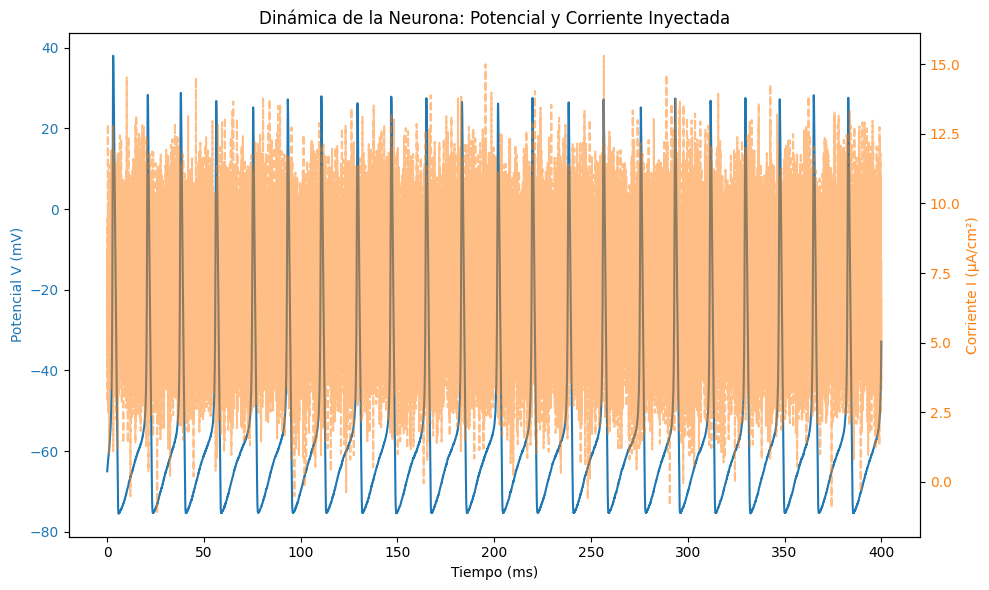

In [59]:
V = hh_multiescala()

Comparación del esuqema multiescala frente al esquema homogéneo:

--- TIEMPOS DE EJECUCIÓN ---
Homogéneo (dt = 0.01 ms total):       1.130419 s
Multiescala (dt_lento=0.1 ms / dt=0.01 ms): 0.567361 s
Factor de velocidad (Homogéneo / Multiescala):     1.99x

--- DISCREPANCIA (Modelo Multiescala vs Modelo Homogéneo) ---
Error Absoluto Medio (MAE):       20.396985 mV
Raíz del Error Cuadrático (RMSE): 32.084405 mV
Diferencia Máxima Puntual:        105.367162 mV


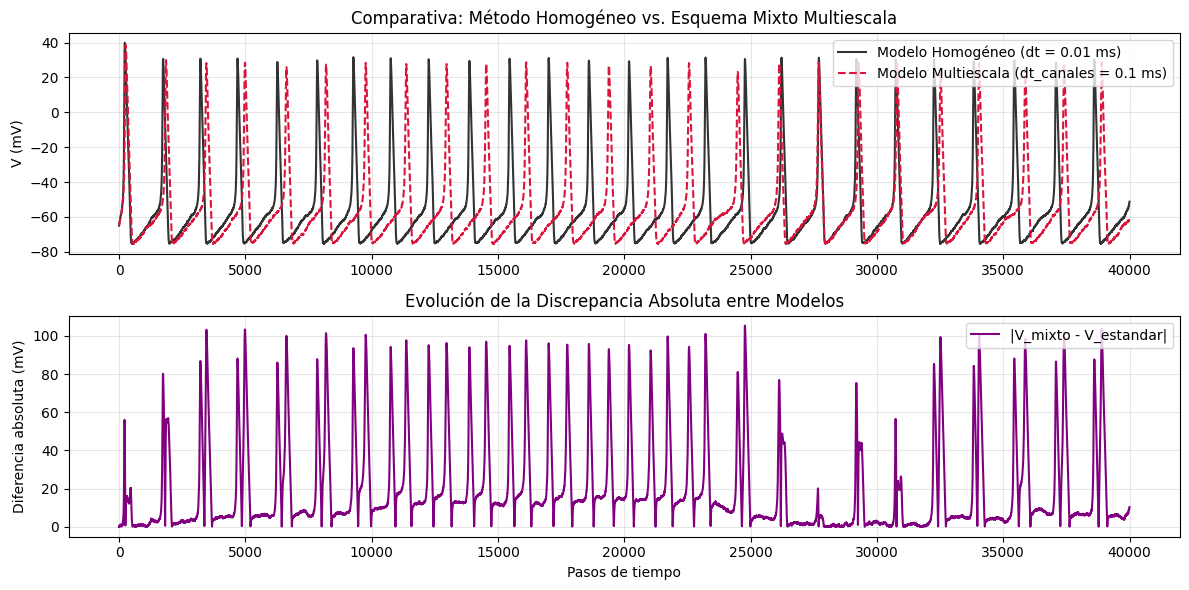

In [56]:
dt_eval = 0.01

# Modelo híbrido pero con mismo paso temporal
t0 = time.perf_counter()
V_estandar = hh_hibrido(dt=dt_eval, sigma=6.0, cte=9.0, plot=False)
t_estandar = time.perf_counter() - t0

# Modelo Multiescala
t0 = time.perf_counter()
V_mixto = hh_multiescala(dt=dt_eval, sigma=6.0, cte=9.0, plot=False)
t_mixto = time.perf_counter() - t0

# Alineación de dimensiones
min_len = min(len(V_estandar), len(V_mixto))
V_estandar = V_estandar[:min_len]
V_mixto = V_mixto[:min_len]

# Cálculo de métricas de discrepancia
error_abs = np.abs(V_mixto - V_estandar)
mae = np.mean(error_abs)
rmse = np.sqrt(np.mean((V_mixto - V_estandar)**2))
max_err = np.max(error_abs)

# Reporte de Tiempos y Métricas
print("--- TIEMPOS DE EJECUCIÓN ---")
print(f"Homogéneo (dt = 0.01 ms total):       {t_estandar:.6f} s")
print(f"Multiescala (dt_lento=0.1 ms / dt=0.01 ms): {t_mixto:.6f} s")

if t_mixto > 0:
    speedup = t_estandar / t_mixto
    print(f"Factor de velocidad (Homogéneo / Multiescala):     {speedup:.2f}x")

print("\n--- DISCREPANCIA (Modelo Multiescala vs Modelo Homogéneo) ---")
print(f"Error Absoluto Medio (MAE):       {mae:.6f} mV")
print(f"Raíz del Error Cuadrático (RMSE): {rmse:.6f} mV")
print(f"Diferencia Máxima Puntual:        {max_err:.6f} mV")


# Representación Gráfica Comparativa
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(V_estandar, label='Modelo Homogéneo (dt = 0.01 ms)', color='black', alpha=0.8)
plt.plot(V_mixto, label='Modelo Multiescala (dt_canales = 0.1 ms)', color='crimson', linestyle='--')
plt.ylabel('V (mV)')
plt.title('Comparativa: Método Homogéneo vs. Esquema Mixto Multiescala')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(error_abs, color='purple', label='|V_mixto - V_estandar|')
plt.xlabel('Pasos de tiempo')
plt.ylabel('Diferencia absoluta (mV)')
plt.title('Evolución de la Discrepancia Absoluta entre Modelos')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()